In [1]:
from fluids.navier import pressure_poisson_jacobi, solve_NS
import numpy as np
import matplotlib.pyplot as plt

In [2]:
Nx, Ny = 101, 101
dx, dy = 0.1, 0.1

x = np.arange(Nx) * dx
y = np.arange(Ny) * dy

Lx = x[-1]
Ly = y[-1]

X, Y = np.meshgrid(x, y, indexing="ij")

p = np.zeros_like(X)

p_exact = (np.cos(np.pi * X / Lx) * np.cos(np.pi * Y / Ly))

f = -((np.pi / Lx) ** 2 + (np.pi / Ly) ** 2) * p_exact

In [3]:
new_p = pressure_poisson_jacobi(p, dx, dy, f, logs=True)

PPE solve iterations = 7822


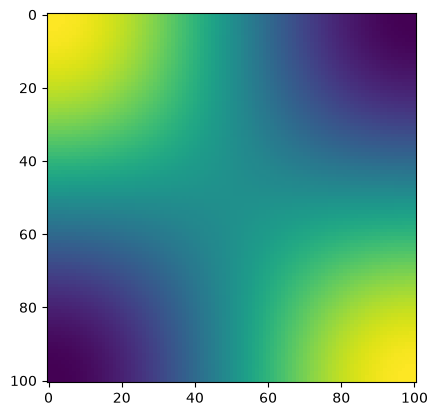

In [4]:
plt.imshow(new_p)

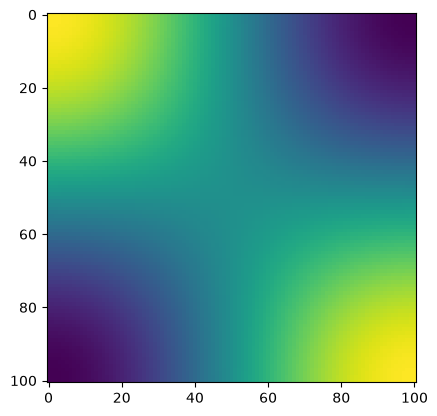

In [5]:
plt.imshow(p_exact)


Time = 0.00100000
PPE solve iterations = 11315
norm(u) = 0.82705004, norm(v) = 0.18249903
Courant number: 0.00806583
velocity residual = 1.321828018254122

Time = 0.00200000
PPE solve iterations = 17847
norm(u) = 0.75128692, norm(v) = 0.24408582
Courant number: 0.00718934
velocity residual = 0.4290229269832597

Time = 0.00300000
PPE solve iterations = 9847
norm(u) = 0.70391939, norm(v) = 0.27665280
Courant number: 0.00664890
velocity residual = 0.24096670148444832

Time = 0.00400000
PPE solve iterations = 1711
norm(u) = 0.67061365, norm(v) = 0.29651965
Courant number: 0.00627018
velocity residual = 0.1616098242957793

Time = 0.00500000
PPE solve iterations = 2056
norm(u) = 0.64563311, norm(v) = 0.30946426
Courant number: 0.00598517
velocity residual = 0.11827121970985133

Time = 0.00600000
PPE solve iterations = 3416
norm(u) = 0.62605073, norm(v) = 0.31817511
Courant number: 0.00576050
velocity residual = 0.0911896128632477

Time = 0.00700000
PPE solve iterations = 2424
norm(u) = 0.61

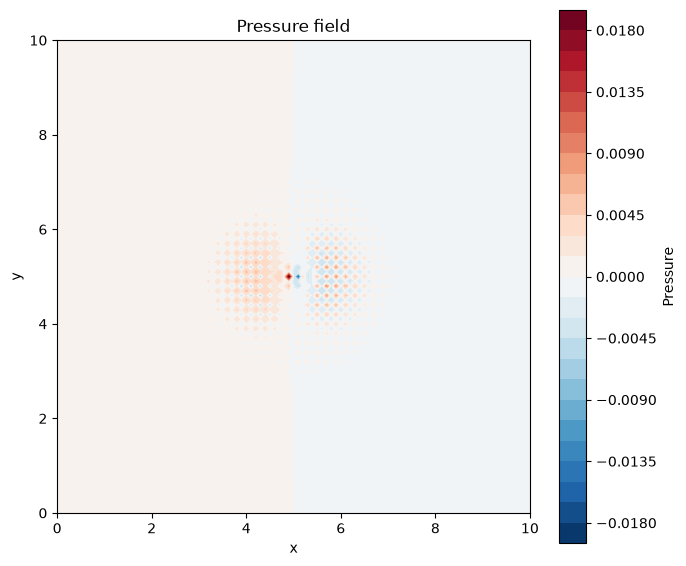

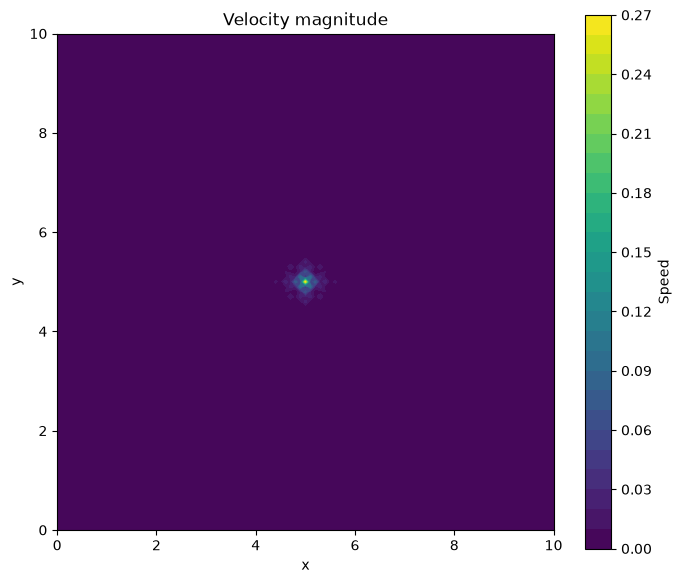

In [6]:
import numpy as np
import matplotlib.pyplot as plt

# Grid
Nx, Ny = 101, 101
dx, dy = 0.1, 0.1

x = np.arange(Nx) * dx
y = np.arange(Ny) * dy
X, Y = np.meshgrid(x, y, indexing="ij")

# Fluid properties
rho = 1.0
nu = 0.01
dt = 0.001
t_end = 0.1

# Initialize fields
u = np.zeros((Nx, Ny))
v = np.zeros((Nx, Ny))
p = np.zeros((Nx, Ny))

# Localized velocity disturbance at the centre
i, j = Nx // 2, Ny // 2
u[i, j] = 1.0

# Run the solver
u, v, p = solve_NS(u, v, p, rho, nu, dt, t_end, dx, dy, logs=True)

# Plot pressure
fig, ax = plt.subplots(figsize=(7, 6))
contour = ax.contourf(X, Y, p, levels=30, cmap="RdBu_r")
fig.colorbar(contour, ax=ax, label="Pressure")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Pressure field")
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

# Plot velocity magnitude
speed = np.sqrt(u**2 + v**2)

fig, ax = plt.subplots(figsize=(7, 6))
contour = ax.contourf(X, Y, speed, levels=30, cmap="viridis")
fig.colorbar(contour, ax=ax, label="Speed")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Velocity magnitude")
ax.set_aspect("equal")
plt.tight_layout()
plt.show()